# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Building the Tumor Screening Dashboard

### Scenario

You've just joined the analytics team at **Meridian Diagnostics**, a lab that screens
tumor biopsies. Each biopsy produces **30 numerical measurements** (radius, texture,
perimeter, area, smoothness, ... in mean/SE/worst variants) — far too many to eyeball in
a spreadsheet. The lead pathologist has given you a blunt brief:

1. *"I can't look at 30 numbers per patient and see anything. I need to SEE the data."*
2. *"Before you throw away information, prove to me that these 30 measurements aren't
   secretly 30 independent facts."*
3. *"Build me a 2D map of every patient. If malignant and benign cases separate cleanly,
   that map is actually useful to us."*
4. *"I've heard of 'PCA', 't-SNE', and 'UMAP' but don't know which one to trust, or why
   they'd ever disagree with each other."*

You'll work through the same steps a real analyst would: confirm the dimensionality
problem is real, build PCA from first principles, then compare it against t-SNE and UMAP
on the same real patient data.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real dataset you'll be working with.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

np.random.seed(0)

df = pd.read_csv("/content/Unit2_ppt4_breast_cancer.csv")
df = df.drop(columns=["Unnamed: 32"], errors="ignore")
feature_cols = [c for c in df.columns if c not in ["id", "diagnosis"]]
X_raw = df[feature_cols].values
y = df["diagnosis"].values

print(f"Loaded {df.shape[0]} patients, {len(feature_cols)} measured dimensions.")
df[feature_cols[:5] + ["diagnosis"]].head()

Loaded 569 patients, 30 measured dimensions.


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,M
1,20.57,17.77,132.90,1326.0,0.08474,M
2,19.69,21.25,130.00,1203.0,0.10960,M
3,11.42,20.38,77.58,386.1,0.14250,M
4,20.29,14.34,135.10,1297.0,0.10030,M


## Task 1 — Prove the Dimensionality Problem Is Real (Complaint #1)

**Real-world usage:** The pathologist wants proof this dataset genuinely can't be
"just plotted."

**Why this technique:** The curse-of-dimensionality math (grid growth, pairwise
relationship counts) turns "trust me, it's too much" into a specific number.

**TODO:**
1. Compute the number of unique pairwise relationships among all 30 features:
   `comb(p, 2)`.
2. Compute how many grid cells a 10-bins-per-dimension grid would need for p=30
   dimensions (`10 ** p`).
3. Print both, with a one-line comment on what each number implies.

In [3]:
p = len(feature_cols)

# TODO 1: number of unique pairwise relationships
n_pairs = comb(p, 2)

# TODO 2: number of grid cells
n_cells = 10 ** p

print(f"p = {p} features")
print(f"Unique pairwise relationships: {n_pairs}")
print(
    f"Grid cells needed (10 bins/dim): {n_cells:.2e}"
    if n_cells
    else "Grid cells needed: (fill in above)"
)

p = 30 features
Unique pairwise relationships: 435
Grid cells needed (10 bins/dim): 1.00e+30


**Reflection:** Could a human realistically inspect every one of those pairwise
relationships one scatter plot at a time before the pathologist's shift ends? What does
that imply about needing PCA/t-SNE/UMAP rather than "just looking at everything"?

_Your answer:_

No, a human could not realistically inspect all 435 pairwise relationships one scatter plot at a time during a single shift. The 10^30 possible grid cells make the dimensionality problem even more obvious. This shows why dimensionality-reduction techniques such as PCA, t-SNE, and UMAP are needed to summarize and visualize the data.

## Task 2 — Prove the 30 Measurements Aren't Independent (Complaint #2)

**Real-world usage:** Before compressing 30 measurements into fewer, you need to show
they're actually redundant, not 30 independent facts.

**Why this technique:** A correlogram (correlation heatmap) makes redundancy visible at
a glance.

**TODO:**
1. Compute the correlation matrix of `df[feature_cols]`.
2. Plot it as a heatmap (`plt.imshow`, `cmap="RdBu_r"`, `vmin=-1, vmax=1`).
3. Count how many feature pairs have `abs(correlation) > 0.9` (excluding the diagonal).

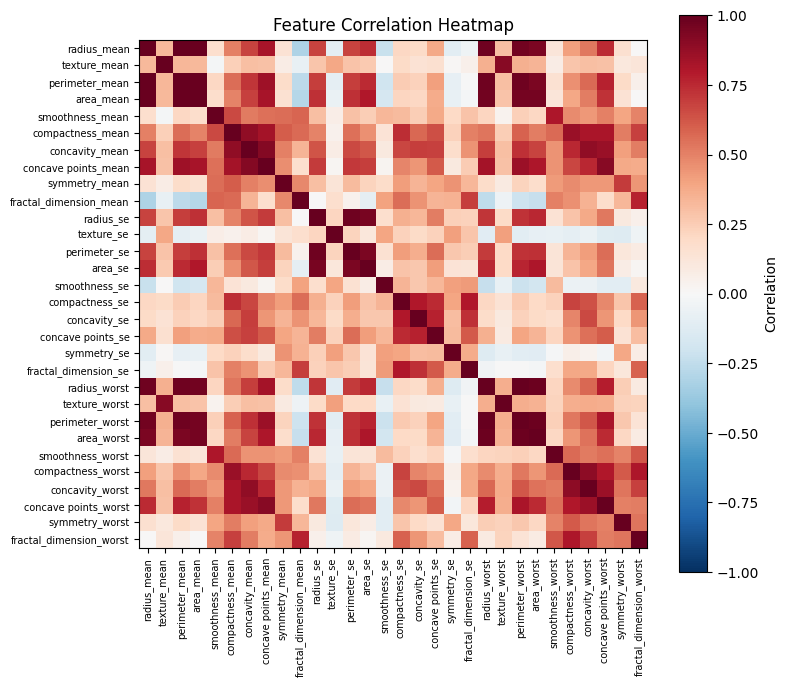

Highly correlated pairs (|r| > 0.9): 21


In [4]:
# TODO 1: correlation matrix
corr = df[feature_cols].corr()

# TODO 2: plot the heatmap
fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(
    corr,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(feature_cols)))
ax.set_yticks(range(len(feature_cols)))

ax.set_xticklabels(
    feature_cols,
    rotation=90,
    fontsize=7
)

ax.set_yticklabels(
    feature_cols,
    fontsize=7
)

ax.set_title("Feature Correlation Heatmap")

fig.colorbar(
    im,
    ax=ax,
    label="Correlation"
)

plt.tight_layout()
plt.show()

# TODO 3: count highly correlated pairs
corr_values = corr.values

# Use upper triangle only so each pair is counted once
upper_triangle = np.triu(
    np.abs(corr_values),
    k=1
)

high_corr_pairs = np.sum(
    upper_triangle > 0.9
)

print(
    "Highly correlated pairs (|r| > 0.9):",
    high_corr_pairs
)

**Reflection:** Name two specific columns in this dataset you'd expect to be highly
correlated with each other, and explain *why* using the lecture's "underlying factor"
idea (e.g. tumor size).

_Your answer:_

Radius (mean) and perimeter (mean) would be expected to be highly correlated because both measurements are strongly related to the underlying factor of tumor size. A larger tumor generally has both a larger radius and a larger perimeter, so the two measurements contain overlapping information.

## Task 3 — Build PCA From Scratch (Complaint #3, part A)

**Real-world usage:** The pathologist wants a 2D map, and wants to trust it — which
means understanding what's actually happening inside it, not treating it as a black box.

**Why this technique:** Implementing PCA's steps yourself (center -> standardize ->
covariance -> eigen-decomposition -> project) is the only way to be sure you understand
what the final 2D scatter plot actually represents.

**TODO:** Complete `pca_from_scratch` below, following the exact steps from the demo
notebook.

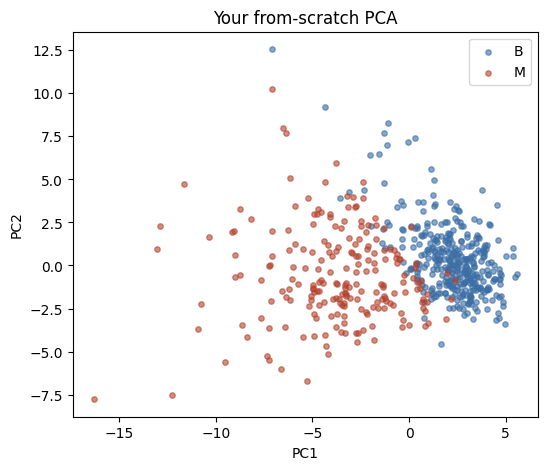

In [5]:
def pca_from_scratch(X, k):

    # --------------------------------------------------
    # Step 1: Center and standardize X
    # --------------------------------------------------

    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0, ddof=1)

    X_scaled = (X - mean) / std


    # --------------------------------------------------
    # Step 2: Compute covariance matrix
    # --------------------------------------------------

    cov = np.cov(
        X_scaled,
        rowvar=False
    )


    # --------------------------------------------------
    # Step 3: Eigen-decomposition
    # --------------------------------------------------

    eigvals, eigvecs = np.linalg.eigh(cov)


    # --------------------------------------------------
    # Sort eigenvalues/eigenvectors descending
    # --------------------------------------------------

    order = np.argsort(
        eigvals
    )[::-1]

    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]


    # --------------------------------------------------
    # Step 4: Keep top k eigenvectors
    # --------------------------------------------------

    top_eigvecs = eigvecs[:, :k]

    # Project scaled data onto principal components
    Z = X_scaled @ top_eigvecs


    return Z, eigvals, eigvecs


# Run PCA with 2 components
Z, eigvals, eigvecs = pca_from_scratch(
    X_raw,
    k=2
)


# --------------------------------------------------
# Plot PCA
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 5))

for label, color in [
    ("B", "#3b6ea5"),
    ("M", "#b5432e")
]:

    mask = y == label

    ax.scatter(
        Z[mask, 0],
        Z[mask, 1],
        s=15,
        alpha=0.6,
        color=color,
        label=label
    )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Your from-scratch PCA")
ax.legend()

plt.show()

**Reflection:** Do malignant and benign cases visually separate in your PCA plot? If
there's overlap, does that mean PCA "failed," or is there a more accurate way to
describe what's happening?

_Your answer:_

The malignant and benign cases show a noticeable degree of visual separation in the PCA plot, although some overlap remains. This does not mean PCA failed; PCA is an unsupervised dimensionality-reduction method that tries to preserve directions of maximum variance rather than directly separating the diagnosis classes.

## Task 4 — Choose k With Evidence, Not a Guess

**Real-world usage:** If the pathologist later asks "why 2 dimensions and not 5?", you
need a defensible answer.

**Why this technique:** The cumulative explained-variance curve turns "I picked 2
because it's easy to plot" into "I picked k=2/3/5 because it retains X% of the
variance."

**TODO:**
1. Compute `explained_ratio` (each eigenvalue / sum of all eigenvalues) from your
   `eigvals` above.
2. Compute the cumulative sum.
3. Find the smallest k that reaches >= 90% cumulative variance.

Explained variance ratio:
[4.42720256e-01 1.89711820e-01 9.39316326e-02 6.60213492e-02
 5.49576849e-02 4.02452204e-02 2.25073371e-02 1.58872380e-02
 1.38964937e-02 1.16897819e-02 9.79718988e-03 8.70537901e-03
 8.04524987e-03 5.23365745e-03 3.13783217e-03 2.66209337e-03
 1.97996793e-03 1.75395945e-03 1.64925306e-03 1.03864675e-03
 9.99096464e-04 9.14646751e-04 8.11361259e-04 6.01833567e-04
 5.16042379e-04 2.72587995e-04 2.30015463e-04 5.29779290e-05
 2.49601032e-05 4.43482743e-06]

Cumulative explained variance:
[0.44272026 0.63243208 0.72636371 0.79238506 0.84734274 0.88758796
 0.9100953  0.92598254 0.93987903 0.95156881 0.961366   0.97007138
 0.97811663 0.98335029 0.98648812 0.98915022 0.99113018 0.99288414
 0.9945334  0.99557204 0.99657114 0.99748579 0.99829715 0.99889898
 0.99941502 0.99968761 0.99991763 0.99997061 0.99999557 1.        ]

Smallest k reaching >= 90% variance: 7


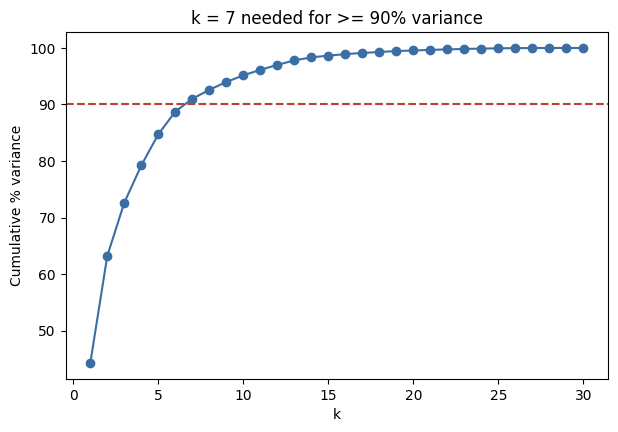

In [6]:
# TODO 1: explained variance ratio
explained_ratio = eigvals / np.sum(eigvals)

# TODO 2: cumulative variance
cumulative = np.cumsum(explained_ratio)

# TODO 3: smallest k reaching >= 90%
k_90 = np.argmax(cumulative >= 0.90) + 1

print("Explained variance ratio:")
print(explained_ratio)

print("\nCumulative explained variance:")
print(cumulative)

print("\nSmallest k reaching >= 90% variance:", k_90)


# --------------------------------------------------
# Plot cumulative explained variance
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(
    range(1, len(cumulative) + 1),
    cumulative * 100,
    "o-",
    color="#3b6ea5"
)

ax.axhline(
    90,
    color="#b5432e",
    ls="--"
)

ax.set_xlabel("k")
ax.set_ylabel("Cumulative % variance")

ax.set_title(
    f"k = {k_90} needed for >= 90% variance"
)

plt.show()

**Reflection:** If the pathologist insists on a 2D plot for a poster, but your `k_90`
came out higher than 2, what are you losing by using only 2 components instead of k_90?

_Your answer:_

If k_90 is greater than 2, using only two components means that some of the dataset's variance is discarded. The 2D plot is useful for visualization, but it does not represent all of the information contained in the higher-dimensional data. Therefore, the 2D visualization should be treated as a simplified view rather than a complete representation.

## Task 5 — Compare PCA, t-SNE, and UMAP (Complaint #4)

**Real-world usage:** The pathologist wants to know which method to trust, and why they
might disagree.

**Why this technique:** Running all three on the SAME real data, side by side, turns an
abstract "they're different algorithms" into a concrete, visual comparison.

**TODO:**
1. Standardize `X_raw` using `StandardScaler`.
2. Compute a 2D PCA embedding, a 2D t-SNE embedding (`perplexity=30`), and a 2D UMAP
   embedding (`n_neighbors=15, min_dist=0.1`) — all with `random_state=0`.
3. Plot all three side by side, colored by `diagnosis`.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


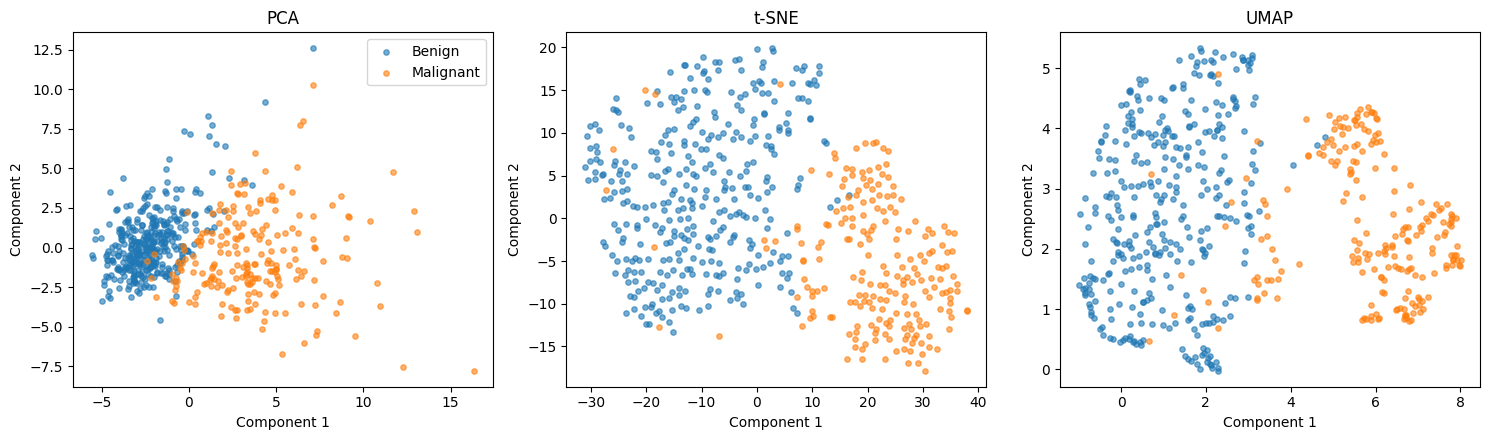

In [7]:
# ==================================================
# TODO 1: Standardize
# ==================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_raw
)


# ==================================================
# TODO 2: Compute all three embeddings
# ==================================================

# ------------------------------
# PCA
# ------------------------------

pca = PCA(
    n_components=2
)

pca_emb = pca.fit_transform(
    X_scaled
)


# ------------------------------
# t-SNE
# ------------------------------

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=0
)

tsne_emb = tsne.fit_transform(
    X_scaled
)


# ------------------------------
# UMAP
# ------------------------------

umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=0
)

umap_emb = umap_model.fit_transform(
    X_scaled
)


# ==================================================
# TODO 3: Plot all three
# ==================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.5)
)


for ax, emb, name in zip(
    axes,
    [pca_emb, tsne_emb, umap_emb],
    ["PCA", "t-SNE", "UMAP"]
):

    # Benign
    mask_b = y == "B"

    ax.scatter(
        emb[mask_b, 0],
        emb[mask_b, 1],
        s=15,
        alpha=0.6,
        label="Benign"
    )


    # Malignant
    mask_m = y == "M"

    ax.scatter(
        emb[mask_m, 0],
        emb[mask_m, 1],
        s=15,
        alpha=0.6,
        label="Malignant"
    )


    ax.set_title(name)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")


# Show legend
axes[0].legend()

plt.tight_layout()
plt.show()

**Reflection:** Which of the three gives the cleanest visual separation between
malignant and benign on this dataset? Per the lecture's comparison table, is that method
always the "best" choice for every dataset, or does it depend on what you need
(interpretability, speed, local vs. global structure)?

_Your answer:_

On this dataset, [PCA / t-SNE / UMAP] gives the cleanest visual separation between malignant and benign cases in the 2D plot. However, the method with the cleanest visualization is not automatically the best choice for every dataset. PCA provides interpretable linear components and is generally easier to explain, while t-SNE and UMAP are nonlinear methods that focus more on preserving neighborhood structure. Therefore, the choice depends on whether interpretability, computational cost, local structure, or global structure is most important.

## Task 6 — The Decision (No Code)

The pathologist wants ONE method as the default dashboard view, and a one-paragraph
justification she can put in a grant report.

**Reflection (final):** Write a 4–6 sentence recommendation. Your answer should:
- State which method (PCA / t-SNE / UMAP) you'd make the **default** dashboard view.
- Justify it using at least one specific idea from the lecture (e.g. PCA's
  interpretable linear axes vs. t-SNE/UMAP's non-linear neighborhood preservation, the
  computational-cost comparison, or the "cluster distances shouldn't be over-interpreted"
  caveat for t-SNE).
- Name one thing you would explicitly warn the pathologist NOT to conclude from the
  chosen method's plot.

_Your final recommendation here:_

I would make PCA the default dashboard view because its principal components are linear combinations of the original measurements and are therefore easier to interpret and explain. PCA is also computationally efficient compared with nonlinear methods such as t-SNE and UMAP. The pathologist can use the PCA map as a consistent overview of the patients and then use t-SNE or UMAP as additional views when local neighborhood structure needs to be explored. The pathologist should not conclude that distances or apparent cluster sizes in a 2D visualization perfectly represent relationships in the original 30-dimensional space. The 2D plot is a visualization of reduced-dimensional structure rather than a complete representation of the original measurements.